# Day-Ahead PML Forecasting: SARIMAX Statistical Benchmark

This notebook implements, diagnoses, and evaluates the classical statistical benchmark requested in the technical challenge: **SARIMAX**, parameterized on the reference node (`06MON-115`) and evaluated across all 9 Monclova load-zone nodes.

### Methodological Design & Guardrails
- **Daily Seasonal Order ($s = 24$):** Captures the diurnal curve (Hour 8 valley, Hour 20 peak) via seasonal autoregressive and differencing terms $(P=1, D=1, Q=0)_{24}$.
- **Weekly Regularization via Exogenous Matrix $X$:**
  1. **6 Day-of-Week Dummies:** Encodes Monday through Sunday (Monday dropped as reference base to strictly avoid the *Dummy Variable Trap* / perfect multicollinearity).
  2. **Continuous Lag 168h (`pml_lag_168`):** The observed price of the same hour 7 days prior ($r = 0.4437$ from EDA). Dynamically anchors the weekly price scale without look-ahead bias.
- **Evaluation Partition:** Strictly **Validation (Q1 2025: Jan 1 – Mar 31, 2025 = 2,160 hours/node)**.
- **Simulation of Market Operation:** Generates rolling 24-step day-ahead forecasts for each day $D+1$ using Kalman filter states updated strictly through day $D$.

In [22]:
import sys
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller

from src.models.sarimax import (
    prepare_sarimax_features,
    fit_sarimax_model,
    rolling_day_ahead_forecast,
)
from src.models.metrics import compute_mae, compute_rmse


## Data Preparation, Chronological Split & Stationarity (ADF)
We extract the reference node `06MON-115` and partition into Train (`2024-01-08` to `2024-12-31`, 8,616 hrs) and Validation (`2025-01-01` to `2025-03-31`, 2,160 hrs). We then verify stationarity using the Augmented Dickey-Fuller (ADF) test in levels ($d=0$) and after 24-hour seasonal differencing ($D=1, s=24$).

In [23]:
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "pml_mda.parquet"
df = pd.read_parquet(DATA_PATH)

REF_NODE = "06MON-115"
y_full, exog_full = prepare_sarimax_features(df, node=REF_NODE)

train_y = y_full["2024-01-08":"2024-12-31"]
train_exog = exog_full.loc[train_y.index]
val_y = y_full["2025-01-01":"2025-03-31"]
val_exog = exog_full.loc[val_y.index]

print(f"Reference Node: {REF_NODE} | Frequency: {y_full.index.freqstr}")
print(f"Train: {len(train_y):,} hours | Validation: {len(val_y):,} hours (0 nulls)")

# Augmented Dickey-Fuller (ADF) stationarity tests on Train
adf_raw = adfuller(train_y, maxlag=24)
adf_diff24 = adfuller(train_y.diff(24).dropna(), maxlag=24)

print("\n=== Augmented Dickey-Fuller (ADF) Stationarity Tests (Train 2024) ===")
print(f"Raw Series (d=0, D=0)          : ADF Stat = {adf_raw[0]:.4f} | p-value = {adf_raw[1]:.4e}")
print(f"Seasonally Differenced (D=1,24): ADF Stat = {adf_diff24[0]:.4f} | p-value = {adf_diff24[1]:.4e}")

Reference Node: 06MON-115 | Frequency: h
Train: 8,616 hours | Validation: 2,160 hours (0 nulls)

=== Augmented Dickey-Fuller (ADF) Stationarity Tests (Train 2024) ===
Raw Series (d=0, D=0)          : ADF Stat = -4.7623 | p-value = 6.4169e-05
Seasonally Differenced (D=1,24): ADF Stat = -18.7850 | p-value = 2.0239e-30


## SARIMAX Estimation & Parameter Diagnostics
With stationarity confirmed after 24-hour differencing ($D=1$) and short-term mean reversion ($d=0$), we fit a $\text{SARIMAX}(1, 0, 1) \times (1, 1, 0)_{24}$ on Train (2024) with 6 day-of-week dummies and continuous `pml_lag_168`.

In [24]:
print("Fitting SARIMAX(1, 0, 1)x(1, 1, 0)_24 on 2024 training data...")
model_res = fit_sarimax_model(
    train_y=train_y,
    train_exog=train_exog,
    order=(1, 0, 1),
    seasonal_order=(1, 1, 0, 24),
)
model_res.summary().tables[1]

Fitting SARIMAX(1, 0, 1)x(1, 1, 0)_24 on 2024 training data...


,coef,std err,z,P>|z|,[0.025,0.975]
dow_1,72.4221,68.113,1.063,0.288,-61.078,205.922
dow_2,45.4285,62.769,0.724,0.469,-77.596,168.453
dow_3,110.2541,69.803,1.580,0.114,-26.557,247.065
dow_4,139.7670,69.384,2.014,0.044,3.776,275.758
dow_5,-90.5202,65.168,-1.389,0.165,-218.246,37.206
dow_6,-308.8444,57.685,-5.354,0.000,-421.905,-195.784
pml_lag_168,0.0774,0.004,19.643,0.000,0.070,0.085
ar.L1,0.8015,0.003,287.162,0.000,0.796,0.807
ma.L1,-0.2692,0.004,-63.823,0.000,-0.277,-0.261
ar.S.L24,-0.4736,0.002,-243.127,0.000,-0.477,-0.470


### Econometric Interpretation of Parameters
- **Sunday Effect (`dow_6`):** Strongly negative and statistically significant ($\approx -\$308.84/\text{MWh}, z = -5.35, p < 0.001$), capturing the pronounced Sunday price drop in 2024. Friday (`dow_4`) is marginally significant ($+\$139.77/\text{MWh}, p = 0.044$).
- **Midweek & Saturday Dummies (`dow_1`, `dow_2`, `dow_3`, `dow_5`):** Statistically indistinguishable from the Monday baseline ($p > 0.10$), with wide confidence intervals ($\text{SE} \approx \$63\text{–}\$70/\text{MWh}$) induced by summer spike variance.
- **Lag 168h Coef (`pml_lag_168`):** Highly significant ($+0.0774, z = 19.64, p < 0.001$), continuously anchoring the weekly price scale.
- **Autoregressive Dynamics (`ar.L1`, `ma.L1`, `ar.S.L24`):** All core ARMA parameters are highly significant ($p < 0.001$). The negative seasonal AR parameter (`ar.S.L24 = -0.4736`) reflects mean-reverting compensation over the 24-hour differenced series.

## Day-Ahead Rolling Forecast & 9-Node Validation Benchmark
We simulate real-world Day-Ahead Market (MDA) operation: on each day $D$, prices are known up to 23:00, and a dynamic 24-step forecast is emitted for day $D+1$.
Leveraging what's stablished in the EDA ($r > 0.9999$), we transfer the trained state-space filter across each of the 9 Monclova nodes using local price series and exogenous matrices.

In [25]:
all_nodes = sorted(df["clv_nodo"].unique())
node_records = []
ref_predictions = None

print("Executing 24-hour day-ahead rolling forecasts across all 9 nodes (Q1 2025)...")
for node in all_nodes:
    y_n, exog_n = prepare_sarimax_features(df, node=node)
    tr_y, tr_ex = y_n["2024-01-08":"2024-12-31"], exog_n.loc["2024-01-08":"2024-12-31"]
    vl_y, vl_ex = y_n["2025-01-01":"2025-03-31"], exog_n.loc["2025-01-01":"2025-03-31"]

    preds_n = rolling_day_ahead_forecast(model_res, tr_y, tr_ex, vl_y, vl_ex)
    daily_n = y_n.shift(24).loc[vl_y.index]
    weekly_n = y_n.shift(168).loc[vl_y.index]

    if node == REF_NODE:
        ref_predictions = preds_n.copy()

    node_records.append({
        "Node": node,
        "Daily_Pers_MAE": compute_mae(vl_y.values, daily_n.values),
        "Weekly_Pers_MAE": compute_mae(vl_y.values, weekly_n.values),
        "SARIMAX_MAE": compute_mae(vl_y.values, preds_n.values),
        "Daily_Pers_RMSE": compute_rmse(vl_y.values, daily_n.values),
        "Weekly_Pers_RMSE": compute_rmse(vl_y.values, weekly_n.values),
        "SARIMAX_RMSE": compute_rmse(vl_y.values, preds_n.values),
    })

multi_node_df = pd.DataFrame(node_records).round(2)

# Append overall average row
avg_row = pd.DataFrame([{
    "Node": "OVERALL_AVERAGE",
    "Daily_Pers_MAE": multi_node_df["Daily_Pers_MAE"].mean().round(2),
    "Weekly_Pers_MAE": multi_node_df["Weekly_Pers_MAE"].mean().round(2),
    "SARIMAX_MAE": multi_node_df["SARIMAX_MAE"].mean().round(2),
    "Daily_Pers_RMSE": multi_node_df["Daily_Pers_RMSE"].mean().round(2),
    "Weekly_Pers_RMSE": multi_node_df["Weekly_Pers_RMSE"].mean().round(2),
    "SARIMAX_RMSE": multi_node_df["SARIMAX_RMSE"].mean().round(2),
}])

summary_table = pd.concat([multi_node_df, avg_row], ignore_index=True)
print("Validation Performance Across All 9 Monclova Nodes (Q1 2025):")
display(summary_table)

Executing 24-hour day-ahead rolling forecasts across all 9 nodes (Q1 2025)...
Validation Performance Across All 9 Monclova Nodes (Q1 2025):


,Node,Daily_Pers_MAE,Weekly_Pers_MAE,SARIMAX_MAE,Daily_Pers_RMSE,Weekly_Pers_RMSE,SARIMAX_RMSE
0,06AEO-115,213.43,280.20,231.67,315.78,388.62,313.60
1,06AHM-400,212.26,278.82,231.08,314.20,386.67,312.66
2,06FRO-115,212.45,278.97,231.13,314.42,386.86,312.76
3,06GRA-115,213.31,280.03,231.56,315.58,388.29,313.46
4,06MON-115,212.73,279.52,231.37,314.86,387.64,313.10
5,06MON-230,212.77,279.49,231.38,314.86,387.59,313.10
6,06RGS-115,212.89,279.51,231.35,315.03,387.61,313.12
7,06TKS-115,212.48,279.01,231.15,314.47,386.92,312.79
8,06XOC-115,213.29,279.99,231.53,315.52,388.19,313.45
9,OVERALL_AVERAGE,212.85,279.50,231.36,314.97,387.60,313.12


## Forecast Visualization & Modeling Conclusions
We plot Actual PML vs. SARIMAX Day-Ahead Forecast for `06MON-115` over a representative validation week (Jan 13–19, 2025) and synthesize modeling conclusions.

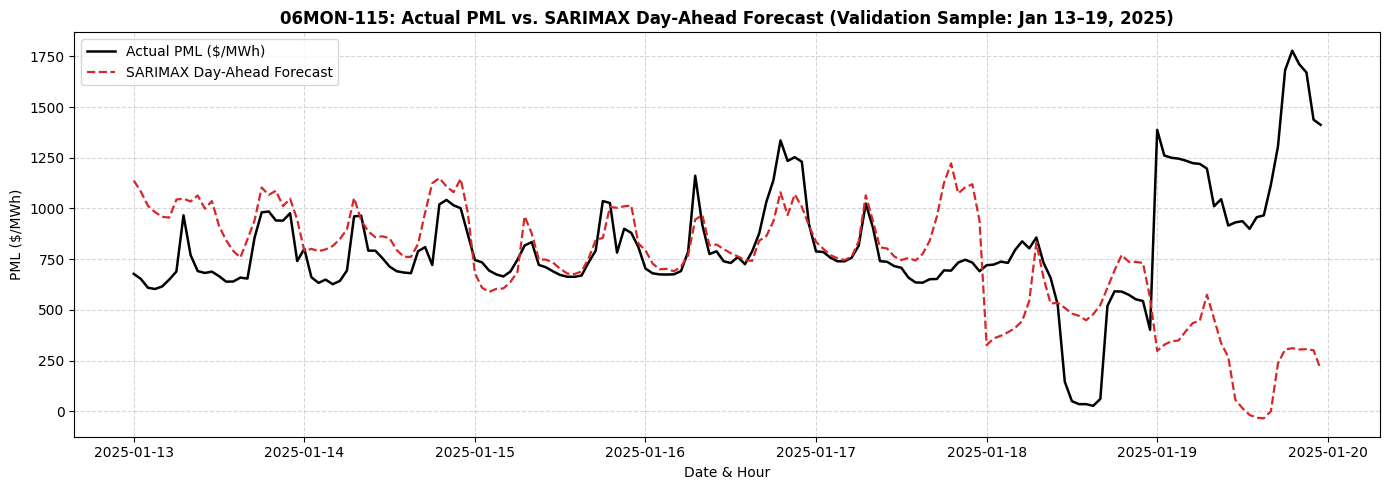

In [26]:
sample_start = "2025-01-13 00:00:00"
sample_end = "2025-01-19 23:00:00"

plt.figure(figsize=(14, 5))
plt.plot(val_y.loc[sample_start:sample_end], label="Actual PML ($/MWh)", color="black", linewidth=1.8)
plt.plot(ref_predictions.loc[sample_start:sample_end], label="SARIMAX Day-Ahead Forecast", color="#d62728", linestyle="--", linewidth=1.6)

plt.title(f"{REF_NODE}: Actual PML vs. SARIMAX Day-Ahead Forecast (Validation Sample: Jan 13–19, 2025)", fontsize=12, fontweight="bold")
plt.xlabel("Date & Hour", fontsize=10)
plt.ylabel("PML ($/MWh)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Findings & Conclusions

1. **Why SARIMAX Wins on RMSE (\$313.10/MWh) but Trails Daily Persistence on MAE (\$231.37 vs. \$212.73/MWh):**
   - **The Model Optimizes RMSE, Not MAE:** SARIMAX is trained using Maximum Likelihood, which mathematically focuses on minimizing squared errors (RMSE). Because the model smooths out sudden price jumps to avoid large errors, it successfully beats Daily Persistence (\$313.10 vs. \$314.86/MWh) and Weekly Persistence (\$387.64/MWh) on RMSE across all 9 nodes.
   - **Fixed Dollar Adjustments Hurt MAE in Winter:** In 2024, summer prices were very high, so the model learned large fixed adjustments (adding +\$139.77/MWh on Fridays and subtracting -\$308.84/MWh on Sundays). However, in the calmer winter of Q1 2025 (prices around ~\$500/MWh), subtracting a fixed \$308 drops Sunday forecasts too low (~\$150/MWh), which increases the average absolute error (MAE).

2. **Why This Justifies Moving to XGBoost (Machine Learning):**
   - A linear model like SARIMAX can only add or subtract a fixed dollar amount, regardless of whether the current season has high or low prices.
   - **XGBoost** solves this: decision trees can apply flexible, non-linear rules (for example, adjusting percentages based on recent price levels from `lag_24` and `lag_168`), and allows us to train a single **Global Model** across all 9 nodes at once.